### INSTALLATION

In [1]:
%pip install tensorflow matplotlib scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


### IMPORT REQUIRED LIBREARY

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import sklearn
from PIL import Image

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.22.0-rc0
All libraries imported successfully!


In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFolders available:")
print(os.listdir())

Current working directory:
C:\Users\USER\Desktop\AJITH\AJITH\deep learning\project\archive

Folders available:
['.ipynb_checkpoints', 'EuroSAT', 'EuroSAT.ipynb', 'eurosat_cnn.keras', 'forest image.jpg', 'Highway image.webp', 'sentinal_satellite_image_classifier.ipynb', 'Sentinel-Satellite-Image-Classification', 'sentinel_2', 'sentinel_satellite_classifier.keras']


In [3]:
dataset_path = os.path.abspath("EuroSAT")

print("Dataset path:", dataset_path)
print("Folder exists:", os.path.isdir(dataset_path))

Dataset path: C:\Users\USER\Desktop\AJITH\AJITH\deep learning\project\archive\EuroSAT
Folder exists: True


In [4]:
expected_classes = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

for class_name in expected_classes:
    folder = os.path.join(dataset_path, class_name)

    if os.path.isdir(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
        ]
        print(f"{class_name}: {len(images)} images")
    else:
        print(f"{class_name}: FOLDER NOT FOUND")

AnnualCrop: 3000 images
Forest: 3000 images
HerbaceousVegetation: 3000 images
Highway: 2500 images
Industrial: 2500 images
Pasture: 2000 images
PermanentCrop: 2500 images
Residential: 3000 images
River: 2500 images
SeaLake: 3000 images


In [5]:
import tensorflow as tf
import os

IMAGE_SIZE = (64, 64)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("\nClasses detected:")
print(class_names)

print("\nNumber of classes:", len(class_names))

Found 27002 files belonging to 10 classes.
Using 21602 files for training.
Found 27002 files belonging to 10 classes.
Using 5400 files for validation.

Classes detected:
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

Number of classes: 10


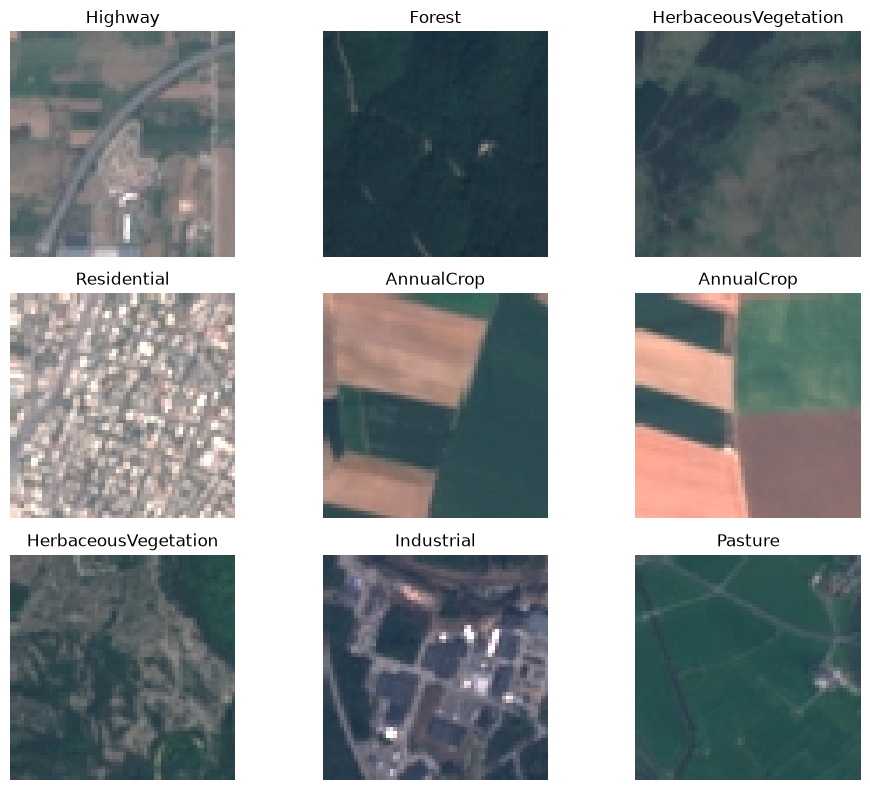

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Data augmentation
augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Improved CNN
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 64, 64, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,946 (437.29 KB)

 Trainable params: 111,498 (435.54 KB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
training_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    ),
    callbacks.ModelCheckpoint(
        "best_eurosat_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=training_callbacks
)

Epoch 1/15


C:\Users\USER\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1351/1351 ━━━━━━━━━━━━━━━━━━━━ 119s 85ms/step - accuracy: 0.6058 - loss: 1.1250 - val_accuracy: 0.4930 - val_loss: 1.6300 - learning_rate: 0.0010
Epoch 2/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 102s 76ms/step - accuracy: 0.7093 - loss: 0.8161 - val_accuracy: 0.7378 - val_loss: 0.7362 - learning_rate: 0.0010
Epoch 3/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 96s 71ms/step - accuracy: 0.7616 - loss: 0.6822 - val_accuracy: 0.4754 - val_loss: 1.7054 - learning_rate: 0.0010
Epoch 4/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 95s 70ms/step - accuracy: 0.7921 - loss: 0.5892 - val_accuracy: 0.8011 - val_loss: 0.5467 - learning_rate: 0.0010
Epoch 5/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 91s 67ms/step - accuracy: 0.8157 - loss: 0.5348 - val_accuracy: 0.8143 - val_loss: 0.6005 - learning_rate: 0.0010
Epoch 6/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 91s 67ms/step - accuracy: 0.8318 - loss: 0.4910 - val_accuracy: 0.8057 - val_loss: 0.5460 - learning_rate: 0.0010
Epoch 7/15
1351/1351 ━━━━━━━━━━━━━━━━━━━━ 92s 68ms/step - accuracy: 0.846

In [9]:
loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation accuracy: {accuracy * 100:.2f}%")

model.save("eurosat_improved.keras")

338/338 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9026 - loss: 0.2833
Validation accuracy: 90.26%


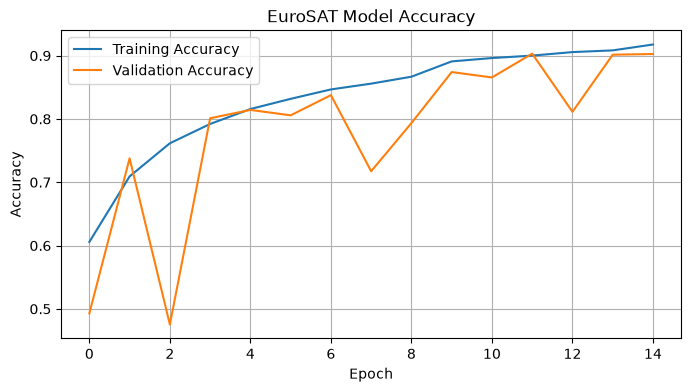

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EuroSAT Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
model.save("eurosat_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import ipywidgets as widgets
from IPython.display import display, clear_output

# Check that the trained model is available
try:
    model
    class_names
except NameError:
    print("ERROR: Model or class names not found.")
    print("Run your model training cells first.")
else:
    output = widgets.Output()

    def predict_image(change):
        with output:
            clear_output(wait=True)

            value = change["new"]

            if not value:
                print("Please upload an image.")
                return

            try:
                # Handle different ipywidgets upload formats
                if isinstance(value, dict):
                    file_info = next(iter(value.values()))
                else:
                    file_info = value[0]

                content = file_info["content"]

                img = Image.open(
                    BytesIO(content)
                ).convert("RGB")

                display(img.copy())

                img_resized = img.resize((64, 64))
                img_array = np.array(
                    img_resized, dtype=np.float32
                )
                img_array = np.expand_dims(
                    img_array, axis=0
                )

                predictions = model.predict(
                    img_array, verbose=0
                )[0]

                index = int(np.argmax(predictions))

                print(
                    "Predicted class:",
                    class_names[index]
                )
                print(
                    f"Confidence: "
                    f"{predictions[index] * 100:.2f}%"
                )

            except Exception as e:
                print("Prediction error:", repr(e))

    upload_new = widgets.FileUpload(
        accept="image/*",
        multiple=False,
        description="Choose Image"
    )

    upload_new.observe(predict_image, names="value")

    display(upload_new, output)

FileUpload(value=(), accept='image/*', description='Choose Image')

Output()

Classification Report:

                      precision    recall  f1-score   support

          AnnualCrop       0.94      0.90      0.92       597
              Forest       0.83      1.00      0.90       600
HerbaceousVegetation       0.94      0.78      0.85       557
             Highway       0.96      0.85      0.90       493
          Industrial       0.93      0.93      0.93       512
             Pasture       0.92      0.83      0.87       374
       PermanentCrop       0.85      0.90      0.87       490
         Residential       0.83      0.99      0.90       608
               River       0.91      0.91      0.91       541
             SeaLake       0.99      0.90      0.95       628

            accuracy                           0.90      5400
           macro avg       0.91      0.90      0.90      5400
        weighted avg       0.91      0.90      0.90      5400



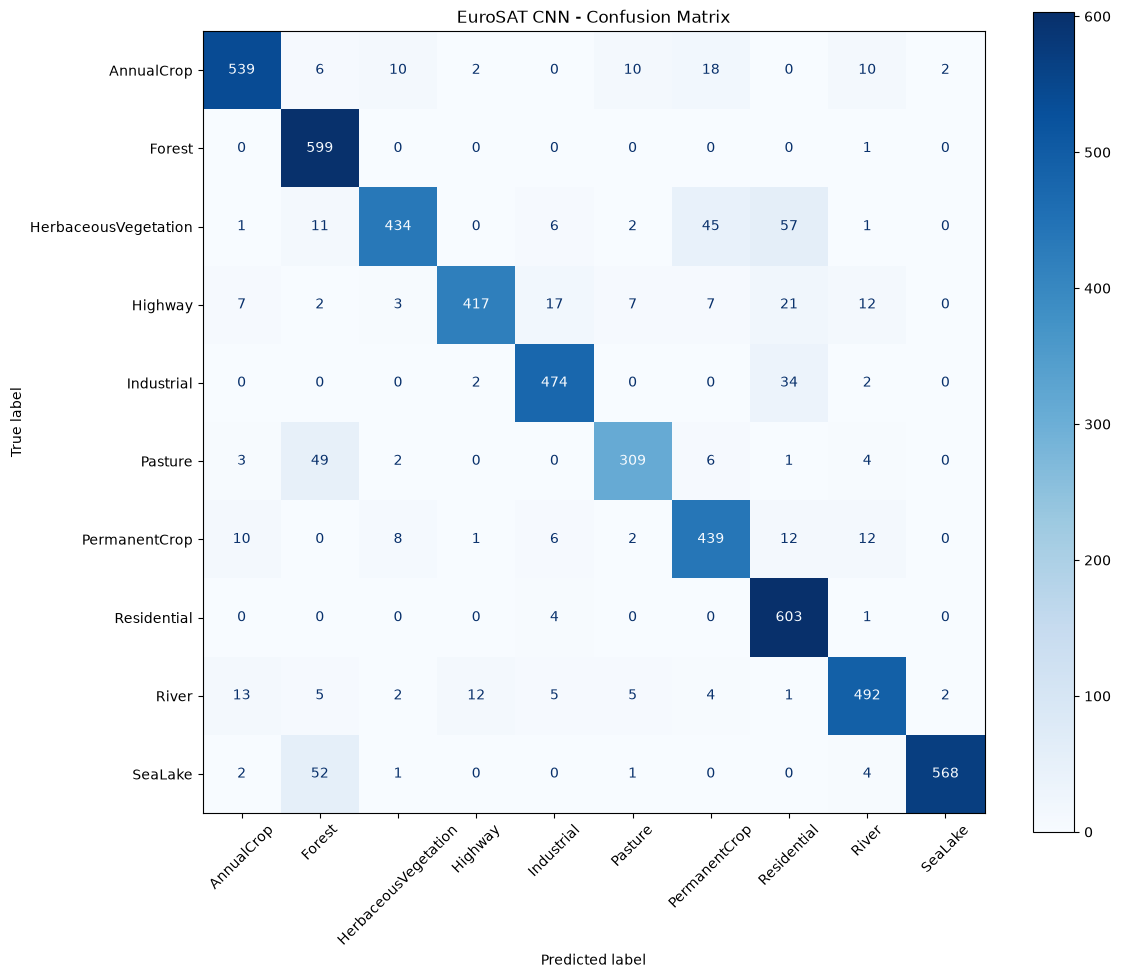

In [14]:
model.save("eurosat_final.keras")
print("Final model saved successfully!")

Final model saved successfully!
